# STAT207 Final Project - SPACE MISSION LAUNCHES

## 1. Introduction

In [167]:
#Imports here
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()
from scipy.stats import norm
from scipy.stats import t
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve

### a. Title: Space Mission Launches

### b. Motivation: Why would someone want to explore our dataset?

Space exploration is constantly advancing in our modern world. From the initial launch of the Sputnik I in 1957 to SpaceX’s most recent Falcon-9 launch this past April, human space exploration has helped us to address fundamental questions about “our place in the Universe and the history of our solar system” (NASA). Assessing different attributes regarding space mission launches helps us conceptualize the progress of competitive exploration on an international scale, as well as predict and analyze the productivity of mission launches themselves. 
https://www.nasa.gov/exploration/whyweexplore/why_we_explore_main.html#.ZEmD6-zMLDI


### c. Research Questions: 

Why would someone be interested? How could our answers be used?

Have space missions gotten safer or has the chance of failure remained unchanged?

What is the relationship between launch success rate and organization? More specifically, how does the relationship between launch success rate and organization change depending on the cost of the mission?


### d. Dataset:

In [168]:
df = pd.read_csv("new_mission_status.csv")

In [169]:
df.head()

,Unnamed: 0,Organisation,Location,Date,Detail,Rocket_Status,Price,Mission_Status,Status,Day,Year,Month,Country
0,0,SpaceX,"LC-39A, Kennedy Space Center, Florida, USA","Fri Aug 07, 2020 05:12 UTC",Falcon 9 Block 5 | Starlink V1 L9 & BlackSky,StatusActive,50.00,Success,1,Fri,2020,Aug,USA
1,1,CASC,"Site 9401 (SLS-2), Jiuquan Satellite Launch Ce...","Thu Aug 06, 2020 04:01 UTC",Long March 2D | Gaofen-9 04 & Q-SAT,StatusActive,29.75,Success,1,Thu,2020,Aug,China
2,3,Roscosmos,"Site 200/39, Baikonur Cosmodrome, Kazakhstan","Thu Jul 30, 2020 21:25 UTC",Proton-M/Briz-M | Ekspress-80 & Ekspress-103,StatusActive,65.00,Success,1,Thu,2020,Jul,Kazakhstan
3,4,ULA,"SLC-41, Cape Canaveral AFS, Florida, USA","Thu Jul 30, 2020 11:50 UTC",Atlas V 541 | Perseverance,StatusActive,145.00,Success,1,Thu,2020,Jul,USA
4,5,CASC,"LC-9, Taiyuan Satellite Launch Center, China","Sat Jul 25, 2020 03:13 UTC","Long March 4B | Ziyuan-3 03, Apocalypse-10 & N...",StatusActive,64.68,Success,1,Sat,2020,Jul,China


In [170]:
df.dtypes

Unnamed: 0          int64
Organisation       object
Location           object
Date               object
Detail             object
Rocket_Status      object
Price             float64
Mission_Status     object
Status              int64
Day                object
Year                int64
Month              object
Country            object
dtype: object

In [171]:
df.mean()

C:\Users\arial\AppData\Local\Temp\ipykernel_3916\3698961737.py:1: FutureWarning: The default value of numeric_only in DataFrame.mean is deprecated. In a future version, it will default to False. In addition, specifying 'numeric_only=None' is deprecated. Select only valid columns or specify the value of numeric_only to silence this warning.
  df.mean()


Unnamed: 0     858.485477
Price          153.792199
Status           0.943983
Year          2007.484440
dtype: float64

In [172]:
df.drop('Unnamed: 0', axis=1, inplace=True)

In [173]:
df.columns

Index(['Organisation', 'Location', 'Date', 'Detail', 'Rocket_Status', 'Price',
       'Mission_Status', 'Status', 'Day', 'Year', 'Month', 'Country'],
      dtype='object')

In [174]:
df["Country"].unique()

array([' USA', ' China', ' Kazakhstan', ' Japan', ' New Zealand',
       ' Russia', ' France', ' India', ' Yellow Sea',
       ' Pacific Missile Range Facility', ' Gran Canaria'], dtype=object)

In [175]:
df["Organisation"].unique()

array(['SpaceX', 'CASC', 'Roscosmos', 'ULA', 'JAXA', 'Northrop', 'ExPace',
       'Rocket Lab', 'Virgin Orbit', 'MHI', 'Arianespace', 'VKS RF',
       'ISRO', 'ILS', 'Eurockot', 'Sandia', 'Kosmotras', 'ESA', 'NASA',
       'Boeing', 'Lockheed', 'EER', 'Martin Marietta', 'RVSN USSR',
       'US Air Force'], dtype=object)

In [176]:
df.std()

C:\Users\arial\AppData\Local\Temp\ipykernel_3916\3390915376.py:1: FutureWarning: The default value of numeric_only in DataFrame.std is deprecated. In a future version, it will default to False. In addition, specifying 'numeric_only=None' is deprecated. Select only valid columns or specify the value of numeric_only to silence this warning.
  df.std()


Price     288.450732
Status      0.230073
Year       12.532855
dtype: float64

In [177]:
df.median()

C:\Users\arial\AppData\Local\Temp\ipykernel_3916\530051474.py:1: FutureWarning: The default value of numeric_only in DataFrame.median is deprecated. In a future version, it will default to False. In addition, specifying 'numeric_only=None' is deprecated. Select only valid columns or specify the value of numeric_only to silence this warning.
  df.median()


Price       62.0
Status       1.0
Year      2011.0
dtype: float64

In [178]:
df.shape

(964, 12)

In [179]:
df['Year'].min()

1964

In [180]:
df['Year'].max()

2020

### e. Think Critically: 
The biggest issue with this data is the lack of numerical variables. I think this data set has a lot of potential to provide insight into the cause of failures and trends of different types of failures with the support of other numerical values collected at launch. I would add more specific information about the different parts of the rocket and how they performed during each launch. This provides insight into what exactly caused each failure. Doing so would also provide interesting insights into how the causes of launch failure changes over time and which countries/organizations have what types of errors. What is nice about this data though is that the data set is quite manageable and it allows for pretty interesting analysis of price and success vs. fail at launch based on variables such as the year, the country the launch took place in, the organization responsible, and much more. If we were to be picky and critical of this dataset, an issue could be that we don't totally know where this information came from; we used kaggle which was recommended by the professor, but there is not much detail on how this data was collected on the posting.


## 2. Descriptive Analytics

In [181]:
df["Country"].value_counts()

 USA                               487
 China                             158
 France                             95
 India                              67
 Russia                             54
 Kazakhstan                         46
 Japan                              40
 New Zealand                        13
 Gran Canaria                        2
 Yellow Sea                          1
 Pacific Missile Range Facility      1
Name: Country, dtype: int64

In [182]:
df["Country"].replace("Yellow Sea", "Other")

0              USA
1            China
2       Kazakhstan
3              USA
4            China
          ...     
959            USA
960            USA
961            USA
962            USA
963            USA
Name: Country, Length: 964, dtype: object

In [183]:
df["Country"].value_counts()

 USA                               487
 China                             158
 France                             95
 India                              67
 Russia                             54
 Kazakhstan                         46
 Japan                              40
 New Zealand                        13
 Gran Canaria                        2
 Yellow Sea                          1
 Pacific Missile Range Facility      1
Name: Country, dtype: int64

In [184]:
df[df.Price==df["Price"].max()]

,Organisation,Location,Date,Detail,Rocket_Status,Price,Mission_Status,Status,Day,Year,Month,Country
888,RVSN USSR,"Site 110/37, Baikonur Cosmodrome, Kazakhstan","Tue Nov 15, 1988 03:00 UTC",Energiya/Buran | Buran,StatusRetired,5000.0,Success,1,Tue,1988,Nov,Kazakhstan
894,RVSN USSR,"Site 250, Baikonur Cosmodrome, Kazakhstan","Fri May 15, 1987 17:30 UTC",Energiya/Polyus | Polyus Space Station,StatusRetired,5000.0,Success,1,Fri,1987,May,Kazakhstan


In [185]:
subdf = df.drop([888,894])

In [186]:
def mysummary(series):
    index = ['min', 'Q1', 'med', 'Q3', 'max', 'mean', 'std']
    value = [series.min(),
            series.quantile(q=0.25),
            series.median(),
            series.quantile(q=0.75),
            series.max(),
            series.mean(),
            series.std()]
    return pd.DataFrame({'value': value}, index=index)

In [187]:
print('Price Summary Values of Mission Successes')
mysummary(df['Price'][df['Mission_Status']=='Success'])

Price Summary Values of Mission Successes


,value
min,5.300000
Q1,40.000000
med,63.955000
Q3,200.000000
max,5000.000000
mean,157.551143
std,293.429514


In [188]:
print('Price Summary Values of Mission Failures')
mysummary(df['Price'][df['Mission_Status']=='Failure'])

Price Summary Values of Mission Failures


,value
min,7.000000
Q1,27.475000
med,40.900000
Q3,60.057500
max,450.000000
mean,67.359444
std,100.985089


Text(0.5, 1.0, 'Retired/Active vs. Mission Cost vs. Success/Failure ')

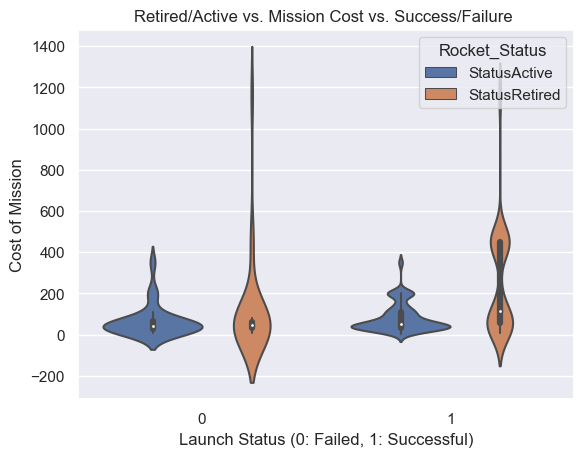

In [189]:
sns.violinplot(x = subdf['Status'], 
            y = subdf['Price'], 
            hue = subdf['Rocket_Status'])
plt.xlabel('Launch Status (0: Failed, 1: Successful)')
plt.ylabel('Cost of Mission')
plt.title('Retired/Active vs. Mission Cost vs. Success/Failure ')

### Research Question: 

What is the relationship between launch success rate and cost of mission? More specifically, how does the relationship between launch success rate and cost change depending on the active or retired status?

The distribution for active, failed missions is right skewed with a median of approximately 50 million dollars and no visible outliers.

The distrubution for failed, retired missions is right skewed with a median of approximately 50 million dollars and an outlier at 1.4 billion dollars.

The distrubution for retired, successful missions are slightly right skewed and bimodal, with a median mission cost of approximately 100 million dollars and an outlier at 1.3 billion dollars.

The distrubution for active, successful missions is right skewed with a median cost of 50 million dollars and no visible outliers, similar to that of active, failed missions.

Per the distributions, retired missions, regardless of success or failure, tend to cost more. Active missions cost less. This could be attributed to the fact that retired missions often require more resources to carry humans, whereas active, currently in-orbit missions are usually satellites which don't have the capacity to support human life, in turn costing less.

Regarding the cost difference for failed versus successful missions, successful mission costs have a median of 63 million dollars with a standard deviation of 293 million dollars, where failed missions have a median cost of 40.9 million dollars with a standard deviation of 100.9 million.

## 3. Inference

### Research Question:

As time went by, the technology improves a lot. So the question arises: have space missions gotten safer or has the chance of failure remained unchanged? To test this, we decide to test whether there is a difference between the launches before 2000 and the launches after 2000 (2000 included) at significance level $\alpha=0.1$

### Hypothesis Test:

$H_0: p_1 = p_2$

$H_a: p_1 < p_2$

where $p_1$ represents the success rate before 2000, and $p_2$ represents the success rate after 2000

In [190]:
before = df[df["Year"]<2000] # dataframe of before 2000
after = df[df["Year"]>=2000] # dataframe of on and after 2000

In [191]:
before_rate = before["Status"].mean()
after_rate = after["Status"].mean()
common_rate = df["Status"].mean()
print(before_rate,after_rate,common_rate)

0.9255813953488372 0.9492656875834445 0.9439834024896265


In [192]:
before_len = len(before)
after_len = len(after)
display(before_len,after_len,before_len*common_rate,after_len*common_rate,before_len*(1-common_rate),after_len*(1-common_rate))

215

749

202.9564315352697

707.0435684647302

12.043568464730296

41.95643153526973

According to the description on Kaggle.come, the total number of space emission launches is about 4000+.

For sample of launches before 2000: 
    
- $n_1 = 215 < 10 \% N $

- $n_1p = 203>10$
    
- $n_1(1-p) = 12 >10$
    

For sample of launches after 2000:

- $n_2 = 749 > 10 \% N $

- $n_2p = 707>10$

- $n_2(1-p) = 42>10$

Two samples are independent.

### P-value Calculation

In [193]:
std = (common_rate*(1-common_rate)*(1/len(before)+1/len(after)))**0.5
std

0.017791760358031594

In [194]:
std = (common_rate*(1-common_rate)*(1/len(before)+1/len(after)))**0.5
z=(before_rate-after_rate)/std # test statistics
norm.cdf(z) # p-value

0.09156252234798745

Based on my 0.01% significance level, we can reject the null hypothesis and conclude that launch mission after 2000 has a higher success rate than before.

### Discussion: 

My hypothesis test shows that the launch mission after 2000 has a higher success rate than before. This indicates that perhaps launches in later years will have a higher chance of successful launch. 

## 4. Linear Regression

### b. Research Questions:
Is there a linear relationship between the price for a rocket launch and the organization in charge of the launch, the year the launch occurred, whether the launch was a success or not, and if the rocket is still active or not. 

### c. 

i. Show the summary output for your linear regression.

In [195]:
import statsmodels.formula.api as smf
results = smf.ols('Price~Organisation+Year+Status+Rocket_Status', data=df).fit()
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Price   R-squared:                       0.925
Model:                            OLS   Adj. R-squared:                  0.923
Method:                 Least Squares   F-statistic:                     429.8
Date:                Wed, 03 May 2023   Prob (F-statistic):               0.00
Time:                        14:28:49   Log-Likelihood:                -5577.1
No. Observations:                 964   AIC:                         1.121e+04
Df Residuals:                     936   BIC:                         1.135e+04
Df Model:                          27                                         
Covariance Type:            nonrobust                                         
===================================================================================================
                                      coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
Intercept                        9568.8533    743.834     12.864      0.000    8109.078     1.1e+04
Organisation[T.Boeing]            -23.8740     32.214     -0.741      0.459     -87.094      39.346
Organisation[T.CASC]             -140.8983     10.384    -13.569      0.000    -161.276    -120.521
Organisation[T.EER]              -221.7662     81.625     -2.717      0.007    -381.955     -61.577
Organisation[T.ESA]              -137.4314     80.350     -1.710      0.088    -295.118      20.255
Organisation[T.Eurockot]         -142.0318     25.156     -5.646      0.000    -191.400     -92.663
Organisation[T.ExPace]           -107.3229     81.255     -1.321      0.187    -266.787      52.141
Organisation[T.ILS]               -86.1842     23.670     -3.641      0.000    -132.636     -39.733
Organisation[T.ISRO]             -141.4260     12.926    -10.941      0.000    -166.793    -116.059
Organisation[T.JAXA]              -85.7420     46.919     -1.827      0.068    -177.821       6.337
Organisation[T.Kosmotras]        -153.0160     20.785     -7.362      0.000    -193.806    -112.226
Organisation[T.Lockheed]         -184.2820     30.882     -5.967      0.000    -244.887    -123.677
Organisation[T.MHI]               -69.8158     15.598     -4.476      0.000    -100.427     -39.204
Organisation[T.Martin Marietta]  -181.9363     29.968     -6.071      0.000    -240.750    -123.123
Organisation[T.NASA]              259.7964     14.915     17.419      0.000     230.526     289.066
Organisation[T.Northrop]         -159.1970     12.449    -12.788      0.000    -183.628    -134.766
Organisation[T.RVSN USSR]        4721.7603     58.350     80.922      0.000    4607.249    4836.272
Organisation[T.Rocket Lab]       -134.7375     23.785     -5.665      0.000    -181.415     -88.060
Organisation[T.Roscosmos]         -93.2972     18.668     -4.998      0.000    -129.932     -56.662
Organisation[T.Sandia]           -143.9725     81.194     -1.773      0.077    -303.315      15.370
Organisation[T.SpaceX]            -91.1553     12.797     -7.123      0.000    -116.269     -66.041
Organisation[T.ULA]               -15.0656     11.517     -1.308      0.191     -37.667       7.536
Organisation[T.US Air Force]     -313.6162     25.130    -12.480      0.000    -362.934    -264.298
Organisation[T.VKS RF]           -109.1258     16.823     -6.487      0.000    -142.140     -76.112
Organisation[T.Virgin Orbit]     -123.6229     81.255     -1.521      0.128    -283.087      35.841
Rocket_Status[T.StatusRetired]    -10.6046      9.020     -1.176      0.240     -28.306       7.097
Year                               -4.6699      0.370    -12.623      0.000      -5.396      -3.944
Status                              1.4492     11.940      0.121      0.903     -21

ii. Write out the linear regression equation for your model. Use appropriate
notation.

$\hat y $= 8521.9021 + 65.1948 * Organisation[T.Boeing] + 887.8742 * Organisation[T.CASC] + -132.3486 *	Organisation[T.EER]	+ -139.3282 * Organisation[T.ESA] + -53.4717 * Organisation[T.Eurockot]	+ 921.6423 * Organisation[T.ExPace]	+ 2.5170 * Organisation[T.ILS] + 443.7356 * Organisation[T.ISRO] + 308.9739 * Organisation[T.JAXA] + -64.2205 * Organisation[T.Kosmotras]+ -95.1686 * Organisation[T.Lockheed] + 325.0257 *	Organisation[T.MHI] + -92.6831 * Organisation[T.Martin Marietta] + 348.9778 * Organisation[T.NASA] + -69.2123 * Organisation[T.Northrop] + 4810.9333 * Organisation[T.RVSN USSR] + 447.0096 * Organisation[T.Rocket Lab] + -4.7579 * Organisation[T.Roscosmos] + 442.5186 * Organisation[T.Sandia] + -2.2894 * Organisation[T.SpaceX] + 73.6580 * Organisation[T.ULA] + -224.1790 * Organisation[T.US Air Force] + -20.6971 *	 Organisation[T.VKS RF] + -34.7394	* Organisation[T.Virgin Orbit] 	+ -10.9162 * Rocket_Status[T.StatusRetired]	+ -4.6610 * Year + 1.7076 * Status	

iii. Check Linear Regression Conditions

Condition 1: Linearity Condition

Points are evenly distributed above and below the line, so this condition is met. 

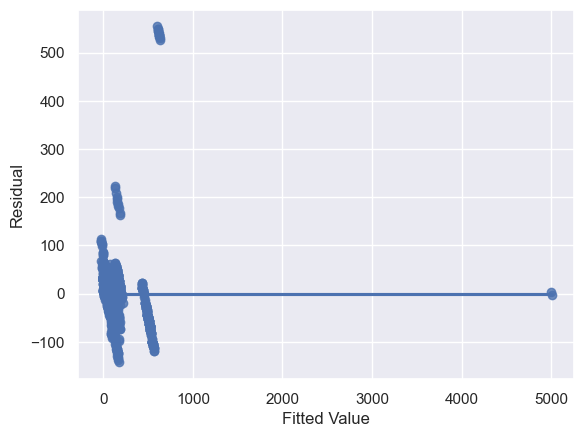

In [196]:
sns.regplot(x=results.fittedvalues, y=results.resid, ci=None)
plt.ylabel('Residual')
plt.xlabel('Fitted Value')
plt.show()

Condition 2: Constant Variability of Residuals Condition

The points y-axis spread of points in the plot below does change from left to right so this condition is not met. 

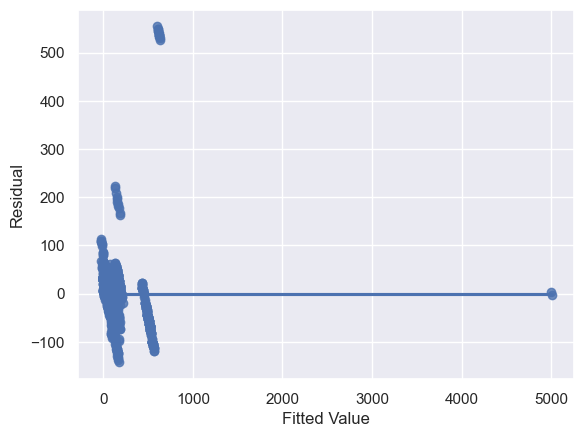

In [197]:
sns.regplot(x=results.fittedvalues, y=results.resid, ci=None)
plt.ylabel('Residual')
plt.xlabel('Fitted Value')
plt.show()

Condition 3: Normality of Residuals (with Mean of 0) Condition

This data is moderately skewed to the right, so the assumption that the residuals are normally distributed are not met.

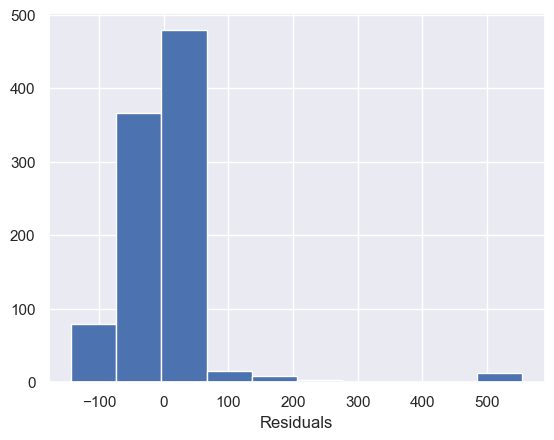

In [198]:
plt.hist(results.resid)
plt.xlabel('Residuals')
plt.show()

Condition 4: Independence of Residuals Condition

The data is randomly sampled and the sample size n=964<10% of all launches

In [199]:
from patsy import dmatrices
from statsmodels.stats.outliers_influence import variance_inflation_factor
y, X = dmatrices('Price~Organisation+Country+Year+Status+Rocket_Status', data=df, return_type='dataframe')
vif_df = pd.DataFrame()
vif_df['variable'] = X.columns 
vif_df['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
vif_df

C:\Users\arial\miniconda3\lib\site-packages\statsmodels\regression\linear_model.py:1752: RuntimeWarning: divide by zero encountered in double_scalars
  return 1 - self.ssr/self.centered_tss
C:\Users\arial\miniconda3\lib\site-packages\statsmodels\stats\outliers_influence.py:195: RuntimeWarning: divide by zero encountered in double_scalars
  vif = 1. / (1. - r_squared_i)


,variable,VIF
0,Intercept,0.000000
1,Organisation[T.Boeing],6.790428
2,Organisation[T.CASC],inf
3,Organisation[T.EER],1.855190
4,Organisation[T.ESA],1.009638
5,Organisation[T.Eurockot],8.573963
6,Organisation[T.ExPace],inf
7,Organisation[T.ILS],8.979802
8,Organisation[T.ISRO],inf
9,Organisation[T.JAXA],inf


Condition 5: No Multicollinearity Condition. All of the numerical data has VIF values below 5, meaning there is no concern for multicollinearity. It would not make sense to look at the VIF value for categorical data. 

(I know we did not learn about VIF in class, but I came across it recently, and thought it would be an interesting way to go about solving this problem)

iv. Discuss what percent of variability in your response variable is explained
by this model in the dataset. Is this high? Is this low?

In [200]:
results_no_org = smf.ols('Price~Country+Year+Status+Rocket_Status', data=df).fit()
results_no_org.rsquared

0.21428744781036524

In [201]:
results_no_count = smf.ols('Price~Organisation+Year+Status+Rocket_Status', data=df).fit()
results_no_count.rsquared

0.9253633317393599

In [202]:
results_no_yr = smf.ols('Price~Organisation+ Country+Status+Rocket_Status', data=df).fit()
results_no_yr.rsquared

0.9131969077354407

In [203]:
results_no_status = smf.ols('Price~Organisation+Country+Year+Rocket_Status', data=df).fit()
results_no_status.rsquared

0.9256146400652436

In [204]:
results_no_rocket_status = smf.ols('Price~Organisation+Country+Year+Status', data=df).fit()
results_no_rocket_status.rsquared

0.9255007885845837

In [205]:
results.rsquared

0.9253633317393599

92.56% of the variabilty in the response variable is explained by this model in the dataset. This is incredibly high and shows a very strong relationship. 

v.

In [253]:
predicting_price = results.predict(exog=dict(Organisation = 'SpaceX', Year= 2019, Status=1, Rocket_Status = 'StatusActive'))
print('Predicted Price: ', predicting_price)

Predicted Price:  0    50.586694
dtype: float64


In [252]:
df_pred_comparison = df[(df.Organisation == 'SpaceX')&(df.Year == 2019) & (df.Status == 1) & (df.Rocket_Status == 'StatusActive')]
df_pred_comparison

,Organisation,Location,Date,Detail,Rocket_Status,Price,Mission_Status,Status,Day,Year,Month,Country
55,SpaceX,"SLC-40, Cape Canaveral AFS, Florida, USA","Tue Dec 17, 2019 00:10 UTC",Falcon 9 Block 5 | JCSAT-18 / Kacific-1,StatusActive,50.0,Success,1,Tue,2019,Dec,USA
60,SpaceX,"SLC-40, Cape Canaveral AFS, Florida, USA","Thu Dec 05, 2019 17:29 UTC",Falcon 9 Block 5 | CRS-19,StatusActive,50.0,Success,1,Thu,2019,Dec,USA
64,SpaceX,"SLC-40, Cape Canaveral AFS, Florida, USA","Mon Nov 11, 2019 14:56 UTC",Falcon 9 Block 5 | Starlink V1 L1,StatusActive,50.0,Success,1,Mon,2019,Nov,USA
85,SpaceX,"SLC-40, Cape Canaveral AFS, Florida, USA","Tue Aug 06, 2019 23:23 UTC",Falcon 9 Block 5 | AMOS-17,StatusActive,50.0,Success,1,Tue,2019,Aug,USA
91,SpaceX,"SLC-40, Cape Canaveral AFS, Florida, USA","Thu Jul 25, 2019 22:01 UTC",Falcon 9 Block 5 | CRS-18,StatusActive,50.0,Success,1,Thu,2019,Jul,USA
96,SpaceX,"LC-39A, Kennedy Space Center, Florida, USA","Tue Jun 25, 2019 06:30 UTC",Falcon Heavy | STP-2,StatusActive,90.0,Success,1,Tue,2019,Jun,USA
99,SpaceX,"SLC-4E, Vandenberg AFB, California, USA","Wed Jun 12, 2019 14:17 UTC",Falcon 9 Block 5 | RADARSAT Constellation,StatusActive,50.0,Success,1,Wed,2019,Jun,USA
102,SpaceX,"SLC-40, Cape Canaveral AFS, Florida, USA","Fri May 24, 2019 02:30 UTC",Falcon 9 Block 5 | Starlink V0.9,StatusActive,50.0,Success,1,Fri,2019,May,USA
106,SpaceX,"SLC-40, Cape Canaveral AFS, Florida, USA","Sat May 04, 2019 06:48 UTC",Falcon 9 Block 5 | CRS-17,StatusActive,50.0,Success,1,Sat,2019,May,USA
110,SpaceX,"LC-39A, Kennedy Space Center, Florida, USA","Thu Apr 11, 2019 22:35 UTC",Falcon Heavy | ArabSat 6A,StatusActive,90.0,Success,1,Thu,2019,Apr,USA


vi.

There are quite a significant number of slopes with a p-value of 0 in the summary table. These are the slopes that have sufficient evidence to suggest they are non-zero in the population mode. Organisation[T.CASC], Organisation[T.Eurockot], Organisation[T.ILS], and the organisation category in general as well as Year both show this. 

## d. 
There is a linear relationship between the price for a rocket launch and the organization in charge of the launch, the year the launch occurred, whether the launch was a success or not, and if the rocket is still active or not. This is shown through the incredibly high r-squared value and the accuracy of the prediction model.

## 5. Logistic Regression

### Research Question

Is there a linear relationship between the log-odds of the success level of mission launches and country, rocket status, year, and price in the sample?

### Train-Test Split

To answer this question, we first divide our dataset into two separate datasets: a training set with 75% of the observations, and a testing set with 25% of the observations.

In [207]:
# Response: Status
# Variable: country, rocket_status, year, price
train, test = train_test_split(df, test_size=0.25, random_state = 207)

### Finding Parsimonious Logistic Regression Model via BIC

In [208]:
model = smf.logit("Status~Price+Country+Year+Rocket_Status",data=train).fit()
print('Iteration 1: BIC of the Current Model:',model.bic)

         Current function value: 0.194721
         Iterations: 35
Iteration 1: BIC of the Current Model: 367.1505636528349


C:\Users\arial\miniconda3\lib\site-packages\statsmodels\base\model.py:604: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [209]:
model = smf.logit("Status~Price+Year+Rocket_Status",data=train).fit()
print('BIC of Test Model that delete Country from the Current Model:',model.bic)

Optimization terminated successfully.
         Current function value: 0.199795
         Iterations 8
BIC of Test Model that delete Country from the Current Model: 315.2372678621483


In [210]:
model = smf.logit("Status~Price+Country+Rocket_Status",data=train).fit()
print('BIC of Test Model that delete Year from Current Model:',model.bic)

         Current function value: 0.196139
         Iterations: 35
BIC of Test Model that delete Year from Current Model: 362.61758815042253


C:\Users\arial\miniconda3\lib\site-packages\statsmodels\base\model.py:604: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [211]:
model = smf.logit("Status~Price+Country+Year",data=train).fit()
print('BIC of Test Model that delete Rocket_Status from Current Model:',model.bic)

         Current function value: 0.197686
         Iterations: 35
BIC of Test Model that delete Rocket_Status from Current Model: 364.85487811565235


C:\Users\arial\miniconda3\lib\site-packages\statsmodels\base\model.py:604: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [212]:
model = smf.logit("Status~Rocket_Status+Country+Year",data=train).fit()
print('BIC of Test Model that delete Country from Current Model:',model.bic)
# error report: singular matrix

         Current function value: 0.202346
         Iterations: 35
BIC of Test Model that delete Country from Current Model: 371.59371631697377


C:\Users\arial\miniconda3\lib\site-packages\statsmodels\base\model.py:604: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


The "test model" that had the lowest BIC score was the one that deleted the "Country"
explanatory variable from the "current model". So we set the new "current model" to be the test model that
does not include "Country" and we go back to another around of backward elimination. 

In [213]:
model = smf.logit("Status~Price+Year+Rocket_Status",data=train).fit()
print('Iteration 2 : BIC of Current Model:',model.bic)

Optimization terminated successfully.
         Current function value: 0.199795
         Iterations 8
Iteration 2 : BIC of Current Model: 315.2372678621483


In [214]:
model = smf.logit("Status~Year+Rocket_Status",data=train).fit()
print('BIC of Test Model that delete Price from Current Model:',model.bic)

Optimization terminated successfully.
         Current function value: 0.207094
         Iterations 7
BIC of Test Model that delete Price from Current Model: 319.20813632554444


In [215]:
model = smf.logit("Status~Price+Rocket_Status",data=train).fit()
print('BIC of Test Model that delete Year from Current Model:',model.bic)

Optimization terminated successfully.
         Current function value: 0.202320
         Iterations 8
BIC of Test Model that delete Year from Current Model: 312.3044862424211


In [216]:
model = smf.logit("Status~Price+Year",data=train).fit()
print('BIC of Test Model that delete Rocket_Status from Current Model:',model.bic)

Optimization terminated successfully.
         Current function value: 0.201586
         Iterations 8
BIC of Test Model that delete Rocket_Status from Current Model: 311.24343758584456


The "test model" that had the lowest BIC score was the one that deleted the "Rocket_Status"
explanatory variable from the "current model". So we set the new "current model" to be the test model that
does not include "Rocket_Status" and we go back to another around of backward elimination. 

In [217]:
model = smf.logit("Status~Price",data=train).fit()
print('BIC of Test Model that delete Year from Current Model:',model.bic)

Optimization terminated successfully.
         Current function value: 0.206848
         Iterations 8
BIC of Test Model that delete Year from Current Model: 312.26915154902986


In [218]:
model = smf.logit("Status~Year",data=train).fit()
print('BIC of Test Model that delete Price from Current Model:',model.bic)

Optimization terminated successfully.
         Current function value: 0.207578
         Iterations 7
BIC of Test Model that delete Price from Current Model: 313.3248448398291


### Parsimonious Logistic Regression Model

In [219]:
final_model = smf.logit("Status~Price+Year",data=train).fit()
final_model.summary()

Optimization terminated successfully.
         Current function value: 0.201586
         Iterations 8


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                 Status   No. Observations:                  723
Model:                          Logit   Df Residuals:                      720
Method:                           MLE   Df Model:                            2
Date:                Wed, 03 May 2023   Pseudo R-squ.:                 0.03989
Time:                        14:28:51   Log-Likelihood:                -145.75
converged:                       True   LL-Null:                       -151.80
Covariance Type:            nonrobust   LLR p-value:                  0.002343
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -63.4422     22.176     -2.861      0.004    -106.906     -19.978
Price          0.0034      0.001      2.352      0.019       0.001       0.006
Year           0.0329      0.011      2.973      0.003       0.011       0.055
==============================================================================
"""

**Logistic Regression equation**: $y = -63.4422 + 0.0034*Price + 0.0329*Year$ where $y=\frac{p}{1-p}$

Since the 95% confidence interval of "Year" and "Price" parameter don't contain, we have sufficient evidence to suggest "Year" and "Price" parameter are non-zero, and therefore are signficant.

### ROC and AUC

In [220]:
test["predict"]=final_model.predict(test)

In [221]:
fpr, tpr, score = roc_curve(y_true=test["Status"],y_score=test["predict"])
auc = roc_auc_score(y_true=test["Status"],y_score=test["predict"])

In [222]:
def plot_roc(fpr, tpr, auc, lw=2):
    plt.plot(fpr, tpr, color='darkorange', lw=lw,label='ROC curve (area = '+str(round(auc,3))+')')
    plt.plot([0, 1], [0, 1], color='navy', lw=lw, linestyle='--' )
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve')
    plt.legend(loc="lower right")
    plt.show()

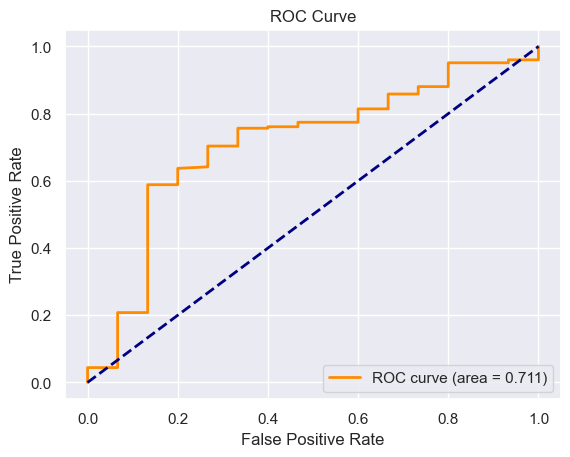

In [223]:
plot_roc(fpr,tpr,auc)

In [224]:
from sklearn.metrics import confusion_matrix
def tpr_fpr_thresh(y, pred_prob, thresh):
    yhat = 1*(pred_prob >= thresh)
    tn, fp, fn, tp = confusion_matrix(y_true=y, y_pred=yhat).ravel()
    tpr = tp / (fn + tp)
    fpr = fp / (fp + tn)
    return thresh, tpr, fpr
data = []
for thresh in np.arange(0,1,.01):
    thres, tpr, fpr = tpr_fpr_thresh(test['Status'], test['predict'], thresh)
    data.append({"thres":thres, "tpr":tpr, "fpr":fpr})
subdf=pd.DataFrame(data)
subdf

,thres,tpr,fpr
0,0.00,1.000000,1.000000
1,0.01,1.000000,1.000000
2,0.02,1.000000,1.000000
3,0.03,1.000000,1.000000
4,0.04,1.000000,1.000000
...,...,...,...
95,0.95,0.646018,0.266667
96,0.96,0.309735,0.133333
97,0.97,0.150442,0.066667
98,0.98,0.044248,0.066667


The optimal threshold is the one with a relatively high tpr and relatively low fpr. To achieve this, a column that measures the difference is added to the dataframe. And we use "thres" with maximum value of tpr minus fpr as the threshold.

In [225]:
subdf["diff"]=subdf["tpr"]-subdf["fpr"]
subdf[subdf["diff"]==subdf["diff"].max()]

,thres,tpr,fpr,diff
95,0.95,0.646018,0.266667,0.379351


In [226]:
test["final_predict"]=test["predict"]>=0.95
tn, fp, fn, tp = confusion_matrix(y_true=test["Status"], y_pred=test["final_predict"]).ravel()
tpr = tp / (fn + tp)
fpr = fp / (fp + tn)
print("The  true positive rate is :", tpr)
print("The  false positive rate is :", fpr)

The  true positive rate is : 0.6460176991150443
The  false positive rate is : 0.26666666666666666


### Discussion

The logistic regression analysis provides edvidence that the variable "Year" and "Price" are factors on whether a mission launches succeed or not. Later years and high perices will generally have a higher rate of launch success. Meanwhile, due to lack of other variables, prediciting success solely on these two variables aren't very accurate. Therefore, more variables should be considered and appended to the dataset.

## Any other type of analysis/question you want to explore with this dataset.

<u>Why?</u>: Sometimes undergraduate students will put the research projects that they did for their classes on their resumes when applying for graduate schools, internships, and jobs. If you're interested in showcasing cool analyses to write on your resume, this section could help with that. **(This section is not worth any points though).**

## 6. Conclusion

Descriptive Analytics: For our analysis, we investigated the relationship between launch success rate and cost of mission--more specifically, how the relationship between launch success rate and cost changes depending on the active or retired status. Per the distributions, retired missions, regardless of success or failure, tend to cost more. Active missions cost less. This could be attributed to the fact that retired missions often require more resources to carry humans, whereas active, currently in-orbit missions are usually satellites which don't have the capacity to support human life, in turn costing less. Regarding the cost difference for failed versus successful missions, we used our summary statistics to determine that successful mission costs have a median of 63 million dollars with a standard deviation of 293 million dollars, where failed missions have a median cost of 40.9 million dollars with a standard deviation of 100.9 million. The 23 million dollar median difference between successful and failed missions implies that less-funded missions have a lower success rate. 

Inference Statistics: As space technology rapidly improves, the question arises: have space missions gotten safer or has the chance of failure remained unchanged? To test this, we decided to test whether there is a difference between the launches before 2000 and the launches after 2000 (2000 included) at significance level $\alpha=0.1$. Our hypothesis test shows that the launch mission after 2000 has a higher success rate than before. This indicates that perhaps launches in later years will have a higher chance of successful launch. 

Linear Regression: We investigated if there is there a linear relationship between the price for a rocket launch and the organization in charge of the launch, the year the launch occurred, whether the launch was a success or not, and if the rocket is still active or not. We ultimately determined that there is indeed a linear relationship between the price for a rocket launch and the organization in charge of the launch, the year the launch occurred, whether the launch was a success or not, and if the rocket is still active or not. This is shown through our incredibly high $r^ 2$ value and the accuracy of the prediction model.

Logistic Regression: Is there a linear relationship between the log-odds of the success level of mission launches and country, rocket status, year, and price in the sample? Our logistic regression analysis provided edvidence that the variable "Year" and "Price" are factors on whether a mission launches succeed or not. Later years and high prices will generally have a higher rate of launch success. Meanwhile, due to lack of other variables, prediciting success solely on these two variables aren't very accurate. Therefore, more variables should be considered and appended to the dataset.

Based on the analyses conducted, there are several avenues for future research that could build upon this work. Some potential research questions and analyses are:

1. Examining the effect of different factors on the outcome variables: Our current analyses focused on the relationship between price, company, and location in relation to mission success or failure. However, it would be interesting to investigate how other variables (e.g., environmental factors and new technological advancement, per se) might also affect these outcomes.

2. Conducting longitudinal studies: Our current analyses were cross-sectional, but potentially conducting longitudinal studies could help us understand how these relationships change over time and whether certain variables are more important at different points in the timeline of space exploration.

3. Developing interventions: Based on the findings of our analyses, it would be valuable to develop and test interventions that target our variables of interest to improve the outcome variables. Evaluating the effectiveness of these interventions could help us understand which factors are most important for mission success rates.